## **🔷 `Week - 1` `Day - 2`**

In [1]:
import json
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import TimeoutError as FutureTimeout

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from llm import llm
from tools import TOOLS

In [2]:
SYSTEM_PROMPT = (
    "You are a helpful assistant. Use tools when you need real data or exact math."
    "If a tool returns an error, read it and try to fix the problem or explain it to the user."
)

MAX_TOOL_OUTPUT = 4000

> **Run one tool call.**

In [3]:
def run_one_tool(tc, tools) -> str:
    name = tc.function.name

    # Failure Case - 1 : Model asked for a tool that doesn't exist
    if name not in tools:
        return f"ERROR : Unknown tool `{name}`. Available tools : {list(tools)}"

    # Failure Case - 2 : The arguments are not valid JSON
    try:
        args = json.loads(tc.function.arguments or "{}")
    except json.JSONDecodeError as e:
        return f"ERROR : Arguments for `{name}` were not valid josn ({str(e)})"

    
    try:
        result = tools[name]['fn'](**args)

    # Failure Case - 3 : Wrong or missing argument names
    except TypeError as e:
        return f"ERROR : Bad arguments for `{name}` : {str(e)}"

    # Failure Case - 4 : The tool itself crashed
    except Exception as e:
        return f"ERROR : Tool `{name}` failed : {type(e).__name__} : {str(e)}"

    text = json.dumps(result, ensure_ascii=False, default = str)
    return text[:MAX_TOOL_OUTPUT]

> **The `agent loop`**

In [4]:
def run_agent(
    task : str, 
    tools : dict, 
    max_steps : int = 8, 
    tool_timeout : int = 20
) -> str:

    schemas = [t["schema"] for t in tools.values()]
    memory = [
        {'role' : 'system', 'content' : SYSTEM_PROMPT},
        {'role' : 'user', 'content' : task}
    ]

    pool = ThreadPoolExecutor(max_workers = 8)

    # ---------- display helpers (output only) ----------
    WIDTH = 64

    def _header(title):
        print()
        print("╔" + "═" * (WIDTH - 2) + "╗")
        print("║ " + title.ljust(WIDTH - 4) + " ║")
        print("╚" + "═" * (WIDTH - 2) + "╝")

    def _section(title):
        print(f"\n┌─ {title}")

    def _line(text, last = False):
        prefix = "└─" if last else "├─"
        print(f"{prefix} {text}")

    def _one_line(text, limit = 150):
        # flatten newlines for display only
        text = " ".join(str(text).split())
        return text[:limit] + ("..." if len(text) > limit else "")

    task_preview = _one_line(task, 120)
    print(f"\n🎯 TASK: {task_preview}")
    print(f"   (max_steps = {max_steps}, tool_timeout = {tool_timeout}s)")

    try:
        for step in range(1, max_steps + 1):
            _header(f"STEP {step} / {max_steps}")

            resp = llm(memory, tools = schemas)
            msg = resp.choices[0].message

            # 1 : No tool is required -> final answer, stop here
            if not msg.tool_calls:
                _header("FINAL ANSWER")
                print(msg.content)
                print("─" * WIDTH)
                return msg.content

            # 2 : Save the model's tool request in memory
            memory.append(
                {
                    'role' : 'assistant',
                    'content' : msg.content,
                    'tool_calls' : [
                        {
                            'id' : tc.id,
                            'type' : 'function',
                            'function' : {'name' : tc.function.name, 'arguments' : tc.function.arguments}
                        } for tc in msg.tool_calls
                    ]
                }
            )

            # 3 : Run all requested tools at the same time
            futures = []
            _section(f"TOOL REQUESTS ({len(msg.tool_calls)})")
            for i, tc in enumerate(msg.tool_calls, 1):
                is_last = (i == len(msg.tool_calls))
                _line(f"[{i}] {tc.function.name}({_one_line(tc.function.arguments, 100)})", last = is_last)
                futures.append((tc, pool.submit(run_one_tool, tc, tools)))

            # 4 : Collect results
            _section(f"TOOL RESULTS ({len(futures)})")
            for i, (tc, fut) in enumerate(futures, 1):
                is_last = (i == len(futures))
                try:
                    result = fut.result(timeout = tool_timeout)
                    status = "✔"
                except FutureTimeout:
                    result = f"ERROR : Tool `{tc.function.name}` timed out after {tool_timeout}s."
                    status = "✘"
                _line(f"{status} [{i}] {tc.function.name}", last = False)
                print(f"{'   ' if is_last else '│  '}   ↳ {_one_line(result)}")
                memory.append(
                    {
                        'role' : 'tool',
                        'tool_call_id' : tc.id,
                        'content' : result
                    }
                )

        # 5 : Hard stop, only reached if the for loop used all its steps
        final_msg = f"STOPPED : Reached max_steps = {max_steps} without a final answer."
        _header("HARD STOP")
        print(final_msg)
        print("─" * WIDTH)
        return final_msg
    finally:
        pool.shutdown(wait = False)

In [5]:
tasks = [
    "Calculate (1234 * 5678) / 12, then take 15% of that result, then subtract 4500 from it.",
    "Get the current weather for Surat, Mumbai, Delhi and Bengaluru. Rank them from hottest to coolest and tell me the average temperature.",
    "Look in my notes for my monthly expenses, add them all up, and tell me what percentage of the total is rent.",
    "Check my trip plan for the cities I want to visit, get the weather for each of them, and recommend which one to visit first.",
    "From the cities in my trip plan, find the one with the highest temperature right now, convert that temperature to Fahrenheit, and tell me if it is above 86 F.",
    "Compare the current weather in Surat and Atlantisville and tell me which is warmer.",
    "Compute 10 / 0 and also 2 ** 1000, then tell me what happened with each one.",
    "In one sentence, explain what a tool call is in an AI agent.",
    "What's the weather there right now?",
    "Search my notes for 'invoice' and tell me the invoice number, amount and due date.",
    "Search my files for 'OPENROUTER_API_KEY' and show me exactly what you find.",
    "Get the weather in Surat, then convert its temperature to Fahrenheit with the calculator, then compare it with 86 F.",
    "Search my files for 'Surat', list every file that mentions it with the line number, and then tell me the current temperature in Surat.",
]

W = 64

for n, t in enumerate(tasks, 1):
    print("\n\n" + "█" * W)
    print(f"█  TASK {n} / {len(tasks)}".ljust(W - 1) + "█")
    print("█" * W)

    answer = run_agent(t, TOOLS)

    print("█" * W)
    print(f"█  END OF TASK {n}".ljust(W - 1) + "█")
    print("█" * W)



████████████████████████████████████████████████████████████████
█  TASK 1 / 13                                                 █
████████████████████████████████████████████████████████████████

🎯 TASK: Calculate (1234 * 5678) / 12, then take 15% of that result, then subtract 4500 from it.
   (max_steps = 8, tool_timeout = 20s)

╔══════════════════════════════════════════════════════════════╗
║ STEP 1 / 8                                                   ║
╚══════════════════════════════════════════════════════════════╝

┌─ TOOL REQUESTS (1)
└─ [1] calculator({"expression":"(1234 * 5678) / 12"})

┌─ TOOL RESULTS (1)
├─ ✔ [1] calculator
      ↳ {"expression": "(1234 * 5678) / 12", "result": 583887.6666666666}

╔══════════════════════════════════════════════════════════════╗
║ STEP 2 / 8                                                   ║
╚══════════════════════════════════════════════════════════════╝

┌─ TOOL REQUESTS (1)
└─ [1] calculator({"expression":"583887.6666666666 * 0.15"})


> **Overall `performance`, `cost` and `latency` calculation**

In [8]:
usd_to_inr_rate = 94.97
total_cost = total_in = total_out = total_time = 0.0
latencies = []
calls = 0
merged_lines = 0

decoder = json.JSONDecoder()
with open("logs/calls.jsonl", encoding="utf-8") as f:
    for line_no, line in enumerate(f, 1):
        line, pos, found = line.strip(), 0, 0
        while pos < len(line):
            try:
                r, pos = decoder.raw_decode(line, pos)
            except json.JSONDecodeError as e:
                print(f"Skipping unreadable data on line {line_no}: {e}")
                break
            found += 1
            total_cost += float(r["cost_usd"])  # cost_usd is stored as text like "0.000039"
            total_in += r["input_tokens"]
            total_out += r["output_tokens"]
            latencies.append(r["latency_s"])
            while pos < len(line) and line[pos].isspace():
                pos += 1
        if found > 1:
            merged_lines += 1
 
if merged_lines:
    print(f"Note: {merged_lines} line(s) had more than one record. Run the repair snippet once.")

calls = len(latencies)
if calls == 0:
    raise SystemExit("No calls logged yet.")
 
mean = np.mean(latencies)
p50, p95 = np.percentile(latencies, [50, 95])

print(f"Calls            :   {calls}")
print(f"Input tokens     :   {int(total_in)}")
print(f"Output tokens    :   {int(total_out)}")
print(f"Total cost (USD) :   ${total_cost:.6f}")
print(f"Total cost (INR) :   ₹{(total_cost * usd_to_inr_rate):.6f}")
print(f"Latency          :   mean {mean:.2f}s | p50 {p50:.2f}s | p95 {p95:.2f}s | "
      f"min {min(latencies):.2f}s | max {max(latencies):.2f}s")

Note: 1 line(s) had more than one record. Run the repair snippet once.
Calls            :   102
Input tokens     :   25625
Output tokens    :   3994
Total cost (USD) :   $0.006241
Total cost (INR) :   ₹0.592708
Latency          :   mean 1.11s | p50 0.96s | p95 1.96s | min 0.67s | max 2.96s


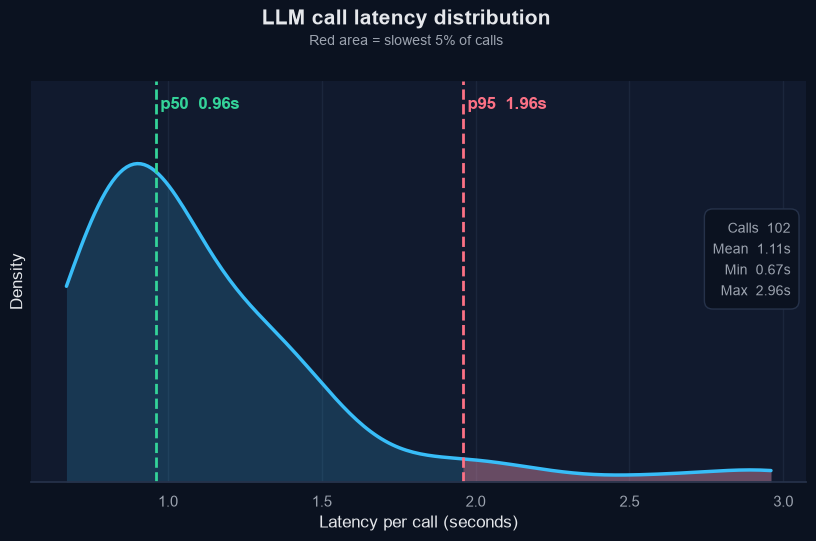

In [9]:
BG, PANEL = "#0B1220", "#111A2E"
TEXT, MUTED, GRID = "#E5E7EB", "#9CA3AF", "#26324A"
CYAN, GREEN, RED = "#38BDF8", "#34D399", "#FB7185"
 
sns.set_theme(style="dark", rc={
    "figure.facecolor": BG, "axes.facecolor": PANEL, "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT, "text.color": TEXT,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
})
fig, ax = plt.subplots(figsize=(10, 5.5))
 
# The KDE curve (cut=0 keeps it inside the real min/max, no negative latency)
sns.kdeplot(latencies, fill=True, alpha=0.18, color=CYAN, linewidth=0,
            bw_adjust=1.0, cut=0, ax=ax)                    # soft fill under the curve
sns.kdeplot(latencies, fill=False, color=CYAN, linewidth=2.5,
            bw_adjust=1.0, cut=0, ax=ax)                    # the curve line itself
 
# Shade the slowest 5% (beyond p95) under the same curve
x, y = ax.lines[0].get_data()
tail = x >= p95
ax.fill_between(x[tail], y[tail], color=RED, alpha=0.35, linewidth=0)
 
# p50 and p95 lines, labelled directly (no legend needed)
ax.set_ylim(0, ax.get_ylim()[1] * 1.2)
top = ax.get_ylim()[1]
ax.axvline(p50, color=GREEN, linestyle="--", linewidth=2)
ax.text(p50 + 0.015, top * 0.96, f"p50  {p50:.2f}s", color=GREEN,
        ha="left", va="top", fontweight="bold")
ax.axvline(p95, color=RED, linestyle="--", linewidth=2)
ax.text(p95 + 0.015, top * 0.96, f"p95  {p95:.2f}s", color=RED,
        ha="left", va="top", fontweight="bold")
 
# Small summary box
summary = (f"Calls  {calls}\nMean  {mean:.2f}s\n"
           f"Min  {min(latencies):.2f}s\nMax  {max(latencies):.2f}s")
ax.text(0.98, 0.66, summary, transform=ax.transAxes, ha="right", va="top",
        fontsize=10, color=MUTED, linespacing=1.6,
        bbox={"boxstyle": "round,pad=0.6", "facecolor": BG, "edgecolor": GRID})
 
ax.set_xlabel("Latency per call (seconds)")
ax.set_ylabel("Density")
ax.set_yticks([])  # density numbers are not meaningful to read
ax.grid(axis="x", alpha=0.5)
sns.despine(ax=ax, left=True)
 
fig.suptitle("LLM call latency distribution", fontsize=15, fontweight="bold", y=0.97)
fig.text(0.5, 0.905, "Red area = slowest 5% of calls", ha="center", fontsize=10, color=MUTED)
fig.subplots_adjust(top=0.84)
 
plt.show()